# Naive Bayes Classifier

**Agenda**

1. Where Naive Bayes fits
2. From Bayes' theorem to the Naive Bayes classifier
3. A worked example: will we play tennis?
4. Two practical problems: zero probabilities and very small numbers
5. Naive Bayes vs kNN vs logistic regression
6. Pros and cons
7. Summary
8. Homework: Naive Bayes on congressional voting records

## Setup: imports and helper code

The helpers draw the figures. You do not need to understand the helper code.

In [1]:
# The imports used in the rest of the notebook
from fractions import Fraction

import matplotlib.pyplot as plt
import numpy as np

In [2]:
# Helper code that can be skipped

def print_probabilities(prior, likelihood, X, feature_names):
    def as_fraction(p):
        return str(Fraction(p).limit_denominator(100))

    print(f"prior: P(Yes) = {as_fraction(prior['Yes'])}, P(No) = {as_fraction(prior['No'])}\n")
    for i, name in enumerate(feature_names):
        print(f"{name:<12} P(value | Yes)  P(value | No)")
        for value in sorted({x[i] for x in X}):
            print(f"  {value:<10} {as_fraction(likelihood[(i, value, 'Yes')]):>13}  "
                  f"{as_fraction(likelihood[(i, value, 'No')]):>13}")


def draw_evidence(prior, likelihood, x, feature_names, positive="No", negative="Yes"):
    # how much each piece of evidence pushes towards one class: log P(value | No) - log P(value | Yes)
    names = ["prior"] + [f"{name} = {value}" for name, value in zip(feature_names, x)]
    pushes = [np.log(prior[positive] / prior[negative])]
    pushes += [np.log(likelihood[(i, v, positive)] / likelihood[(i, v, negative)]) for i, v in enumerate(x)]
    fig, ax = plt.subplots(figsize=(9, 3.6))
    colours = ["#c62828" if push > 0 else "#1f4e79" for push in pushes]
    ax.barh(names[::-1], pushes[::-1], color=colours[::-1])
    ax.axvline(0, color="black", lw=1)
    ax.set_xlabel(f"← towards Play = {negative}        log-ratio        towards Play = {positive} →")
    ax.set_title(f"Total: {sum(pushes):+.2f} → Play = {positive if sum(pushes) > 0 else negative}")
    plt.close(fig)
    return fig

---

# 1. Where Naive Bayes fits

The **Naive Bayes classifier** is:

- **supervised learning** - it learns from labelled examples
- a **classification** algorithm - it predicts a class (spam / not spam, Democrat / Republican)
- **global** learning - it learns from **all** the training examples at once (kNN looks only at a few neighbours)
- **model-based** and **eager** - it builds a model **before** it sees any new example (kNN just stores the data)

Its model is a set of **probabilities**, estimated by **counting** in the training data. To predict, it asks: "which
class is the **most probable**, given what I see in this example?" To answer that, we need a little probability, and
**Bayes' theorem**.

---

# 2. From Bayes' theorem to Naive Bayes

## 2.1 The classification question

An example is described by $n$ features $x = (x_1, \dots, x_n)$. Suppose we want to classify an example to one of the given classes $C_1, \dots, C_K$. For each class $C_k$ we want to find the probability $P(C_k \mid x_1, \dots, x_n)$, and then we pick the most probable class. By Bayes' theorem:

$$P(C_k \mid x) = \frac{P(C_k) \cdot P(x \mid C_k)}{P(x)}$$

- $P(x)$ is the same for every class (it does not depend on $C_k$). It does not change **which** class
  is the largest, so we can ignore it. What remains, $P(C_k) \cdot P(x \mid C_k)$, is the joint probability
  $P(C_k, x_1, \dots, x_n)$.
- $P(C_k)$ is easy, it is the fraction of training examples in class $C_k$.
- $P(x_1, \dots, x_n \mid C_k)$ is the problem: the probability of this **exact combination** of all $n$ feature values in class $C_k$.

**Why is calculating $P(x_1, \dots, x_n \mid C_k)$ a problem?** To estimate it by counting, we would need many training examples with exactly
this combination. With 16 yes / no features there are $2^{16} = 65{,}536$ combinations per class, and the homework
dataset has only 435 examples. Most combinations never appear in the data, so we cannot count them.

## 2.2 The "naive" assumption

To make calculating $P(x_1, \dots, x_n \mid C_k)$ easier, we make a **naive** assumption that **all of the features are conditionally independent of each other**. This means that:

$$P(x_i, x_j \mid C_k) = P(x_i \mid C_k)P(x_j \mid C_k)$$

Conditionally independent means that $x_i$ and $x_j$ are independent, **given the class $C_k$**. Generally, if the class is not given, we cannot say that $x_i$ and $x_j$ are independent.

For all of the features, the formula becomes:

$$P(x_1, \dots, x_n \mid C_k) = \prod_{i=1}^{n} P(x_i \mid C_k)$$

This assumption makes the calculation feasible, because each $P(x_i \mid C_k)$ needs only enough examples of **one feature value** in one class, which is easy to count.

When we substitute in Bayes' formula, we get the following:

$$P(C_k \mid x) = \frac{P(C_k) \cdot P(x_1, \dots, x_n \mid C_k)}{P(x)} = \frac{P(C_k) \cdot \prod_{i=1}^{n} P(x_i \mid C_k)}{P(x)} \propto P(C_k) \cdot \prod_{i=1}^{n} P(x_i \mid C_k)$$

## 2.3 The decision rule

As we said earlier, **the denominator is the same for every class**, so we can just look at the numerator to see which class has highest probability.

Our prediction will be:

$$\hat{y} = \underset{k \in \{1, \dots, K\}}{\operatorname{argmax}} \; P(C_k) \prod_{i=1}^{n} P(x_i \mid C_k)$$

Which is just the class $k$ that has the highest probability.

So the whole classifier is:

- **Training**: For every class, count the class frequency, which is used to get $P(C_k)$. For every feature, count the value frequencies within each class, which is used to get $P(x_i \mid C_k)$.
- **Prediction**: Use the prediction formula above, and pick the class with the biggest product.

---

# 3. Example

## 3.1 The data

 4 categorical features, and the class "do we play tennis?":

|Outlook | Temperature | Humidity | Wind | Play |
|---|---|---|---|---|
| Sunny | Hot | High | Weak | No |
| Sunny | Hot | High | Strong | No |
| Overcast | Hot | High | Weak | Yes |
| Rain | Mild | High | Weak | Yes |
| Rain | Cool | Normal | Weak | Yes |
| Rain | Cool | Normal | Strong | No |
| Overcast | Cool | Normal | Strong | Yes |
| Sunny | Mild | High | Weak | No |
| Sunny | Cool | Normal | Weak | Yes |
| Rain | Mild | Normal | Weak | Yes |
| Sunny | Mild | Normal | Strong | Yes |
| Overcast | Mild | High | Strong | Yes |
| Overcast | Hot | Normal | Weak | Yes |
| Rain | Mild | High | Strong | No |

The new day: $x_t$ = (Outlook = Sunny, Temperature = Cool, Humidity = High, Wind = Strong). Play or not?

The probabilities we need:

- **the class probabilities** $P(C_k)$: $P(\text{Play} = \text{Yes})$ and $P(\text{Play} = \text{No})$
- **the feature probabilities** $P(x_i \mid C_k)$: e.g. $P(\text{Outlook} = \text{Sunny} \mid \text{Play} = \text{Yes})$ - for every
  value of every feature, in each of the two classes

In [3]:
feature_names = ("Outlook", "Temperature", "Humidity", "Wind")
tennis_days = [
    ("Sunny", "Hot", "High", "Weak", "No"), ("Sunny", "Hot", "High", "Strong", "No"),
    ("Overcast", "Hot", "High", "Weak", "Yes"), ("Rain", "Mild", "High", "Weak", "Yes"),
    ("Rain", "Cool", "Normal", "Weak", "Yes"), ("Rain", "Cool", "Normal", "Strong", "No"),
    ("Overcast", "Cool", "Normal", "Strong", "Yes"), ("Sunny", "Mild", "High", "Weak", "No"),
    ("Sunny", "Cool", "Normal", "Weak", "Yes"), ("Rain", "Mild", "Normal", "Weak", "Yes"),
    ("Sunny", "Mild", "Normal", "Strong", "Yes"), ("Overcast", "Mild", "High", "Strong", "Yes"),
    ("Overcast", "Hot", "Normal", "Weak", "Yes"), ("Rain", "Mild", "High", "Strong", "No"),
]
tennis_X = [day[:4] for day in tennis_days]          # the features
tennis_y = [day[4] for day in tennis_days]           # the class

## 3.2 Training = counting

In [4]:
def train_naive_bayes(X, y):
    classes = sorted(set(y))                                              # the classes
    n_features = len(X[0])                                                # number of features
    values = [{x[i] for x in X} for i in range(n_features)]               # the possible values of every feature
    class_probs, feature_probs = {}, {}
    for C_k in classes:
        rows = [x for x, label in zip(X, y) if label == C_k]              # the training examples of class C_k
        class_probs[C_k] = len(rows) / len(X)                             # P(C_k)
        for i in range(n_features):
            for v in values[i]:
                count = sum(1 for x in rows if x[i] == v)                 # the number of training examples of class C_k that have value v for feature i
                feature_probs[(i, v, C_k)] = count / len(rows)            # P(X_i = v | C_k)
    return class_probs, feature_probs


def naive_bayes_scores(class_probs, feature_probs, x):
    # P(C_k) * P(x_1 | C_k) * ... * P(x_n | C_k) for every class C_k - the numerator of Bayes' theorem
    return {C_k: class_probs[C_k] * np.prod([feature_probs[(i, v, C_k)] for i, v in enumerate(x)]) for C_k in class_probs}

In [5]:
tennis_prior, tennis_likelihood = train_naive_bayes(tennis_X, tennis_y)
print_probabilities(tennis_prior, tennis_likelihood, tennis_X, feature_names)

prior: P(Yes) = 9/14, P(No) = 5/14

Outlook      P(value | Yes)  P(value | No)
  Overcast             4/9              0
  Rain                 1/3            2/5
  Sunny                2/9            3/5
Temperature  P(value | Yes)  P(value | No)
  Cool                 1/3            1/5
  Hot                  2/9            2/5
  Mild                 4/9            2/5
Humidity     P(value | Yes)  P(value | No)
  High                 1/3            4/5
  Normal               2/3            1/5
Wind         P(value | Yes)  P(value | No)
  Strong               1/3            3/5
  Weak                 2/3            2/5


Each number is a simple count. There are 9 "Yes" days, and 2 of them are Sunny (days 9 and 11), so
$P(\text{Sunny} \mid \text{Yes}) = \frac{2}{9}$. There are 5 "No" days, and 3 of them are Sunny (days 1, 2, 8), so
$P(\text{Sunny} \mid \text{No}) = \frac{3}{5}$.

> **This table is the model.**

## 3.3 Classifying the new day

In [6]:
new_day = ("Sunny", "Cool", "High", "Strong") # a new day for which we want to predict whether to play tennis or not

tennis_scores = naive_bayes_scores(tennis_prior, tennis_likelihood, new_day)

for _c, _score in tennis_scores.items():
    print(f"P(Play = {_c}) · P(Sunny | {_c}) · P(Cool | {_c}) · P(High | {_c}) · P(Strong | {_c}) = {_score:.4f}")

print("\nprediction:", max(tennis_scores, key=tennis_scores.get))
print("normalized:", {C_k: f"{score / sum(tennis_scores.values()):.1%}" for C_k, score in tennis_scores.items()})

P(Play = No) · P(Sunny | No) · P(Cool | No) · P(High | No) · P(Strong | No) = 0.0206
P(Play = Yes) · P(Sunny | Yes) · P(Cool | Yes) · P(High | Yes) · P(Strong | Yes) = 0.0053

prediction: No
normalized: {'No': '79.5%', 'Yes': '20.5%'}


$$P(\text{Yes} \mid x_t) \propto \frac{2}{9} \cdot \frac{3}{9} \cdot \frac{3}{9} \cdot \frac{3}{9} \cdot \frac{9}{14} = 0.0053
\qquad P(\text{No} \mid x_t) \propto \frac{3}{5} \cdot \frac{1}{5} \cdot \frac{4}{5} \cdot \frac{3}{5} \cdot \frac{5}{14} = 0.0206$$

$0.0053 < 0.0206$, so we classify the new day as **No**.

**The two numbers are not probabilities because we skipped dividing by $P(x_t)$**. We can get the real probabilities by dividing each score by their sum: $\frac{0.0206}{0.0053 + 0.0206} \approx 79.5\%$ for "No".

**How did each feature vote?** We can take the logarithm of the ratio $x = \frac{P(\text{value} \mid \text{No})}{P(\text{value} \mid
\text{Yes})}$ to compare whether the feature pushes towards "No" or towards "Yes". We take the log, because $log(x) > 0$ for $x > 1$ and $log(x) < 0$ for $x < 1$, so adding the log of each feature ratio "pushes" the sum either left or right:

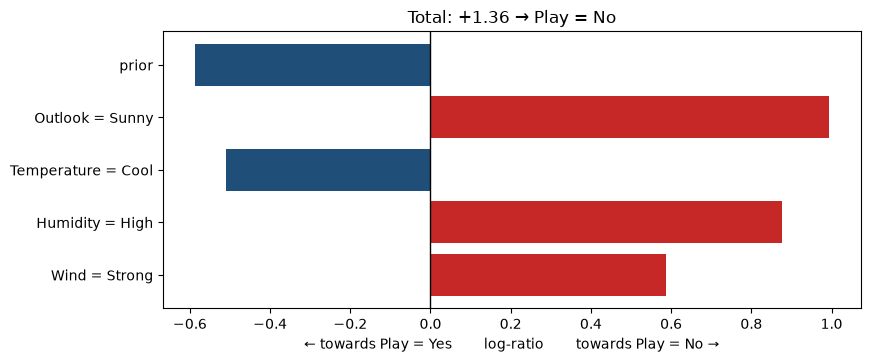

In [7]:
draw_evidence(tennis_prior, tennis_likelihood, new_day, feature_names)

The prior favours "Yes" (9 of 14 days were "Yes"), but Sunny, High humidity and Strong wind all point towards "No",
and together they win. Only Cool points towards "Yes". This is exactly how Naive Bayes thinks: **every
feature is a separate piece of evidence, and the evidence adds up**.

---

# 4. Two practical problems

## 4.1 The zero probability problem

If we look at the Outlook table again, we can see that no "No" day was Overcast, so $P(\text{Overcast} \mid \text{No}) = \frac{0}{5} = 0$. A
single zero makes the whole product zero, because for **any** Overcast day, "No" gets probability 0, no matter how strong the other features are.

**Laplace smoothing** adds a small number $\lambda$ (usually 1) to every count, as if we had seen
every value $\lambda$ more times:

$$P(C_k) = \frac{N_{C_k} + \lambda}{N + K \lambda} \qquad P(x_i = a \mid C_k) = \frac{N_{C_k, \, x_i = a} + \lambda}{N_{C_k} + A \lambda}$$

- $N$ - the number of training examples, $N_{C_k}$ - the number of examples of class $C_k$
- $N_{C_k, \, x_i = a}$ - the number of examples of class $C_k$ where feature $i$ has the value $a$
- $K$ - the number of classes, $A$ - the number of different values of feature $i$

Adding $A \lambda$ to the denominator keeps the probabilities of all values summing to 1. E.g. Outlook has $A = 3$
values, so $P(\text{Overcast} \mid \text{No}) = \frac{0 + 1}{5 + 3} = \frac{1}{8}$, which is small, but not impossible.

## 4.2 Very small numbers: use logarithms

The product shrinks with every feature: $0.1 \cdot 0.2 = 0.02$, $\cdot 0.3 = 0.006$,
$\cdot 0.4 = 0.0024$, and so on. With hundreds of features, the product becomes
smaller than the smallest number a computer can store, and is rounded to exactly 0 for **every** class - this is called
**underflow**:

In [8]:
_probabilities = np.full(400, 0.1) # [0.1, 0.1, 0.1, ..., 0.1] - 400 times
print("product of 400 probabilities:  ", np.prod(_probabilities))
print("sum of their logarithms:       ", np.sum(np.log(_probabilities)))

product of 400 probabilities:   0.0
sum of their logarithms:        -921.0340371976183


To fix this, we can use the log property $\log(ab) = \log(a) + \log(b)$ to take the logarithm of the score and **add** instead of multiply:

$$\hat{y} = \underset{k}{\operatorname{argmax}} \; \left[ \log P(C_k) + \sum_{i=1}^{n} \log P(x_i \mid C_k) \right]$$

The logarithm is an increasing function, so the class with the biggest product also has the biggest sum of logs. The
prediction does not change, but the numbers stay in a normal range.

---

# 5. Naive Bayes vs kNN vs logistic regression

| | Naive Bayes | kNN | Logistic regression |
|---|---|---|---|
| **Task** | classification | classification and regression | classification |
| **Parametric?** | yes - a fixed table of probabilities | no - stores all the data | yes - $n + 1$ weights |
| **Global / local** | global | local | global |
| **Training** | counting - one pass over the data, very fast | none | gradient descent - many iterations |
| **Prediction** | fast: one sum per class | slow: a distance to every training point | fast |
| **Outputs probabilities?** | yes | the fraction of neighbours | yes |
| **Many features (e.g. text)?** | works very well | suffers (curse of dimensionality) | works well |
| **Feature scaling** | not needed | essential | helps |
| **Main assumption** | the features are independent given the class | similar examples have similar labels | the classes are separated by a straight line|

---

# 6. Pros and cons of Naive Bayes

| Pros | Cons |
|---|---|
| very fast training: one pass of counting over the data | the independence assumption is almost never true |
| very fast prediction: one sum per class | the probabilities are unreliable - often too close to 0 or 1 |
| needs little training data - every probability involves only one feature | a value never seen in training gives 0 - needs smoothing |
| works with many features (thousands of words) - no curse of dimensionality | cannot learn interactions between features (e.g. XOR: only the **combination** of two features matters) |
| naturally handles any number of classes | ignores word order if we have words as features |
| no feature scaling needed; easy to add new data (update the counts) | sensitive to imbalanced classes, because $P(C_k)$ favours the bigger class |
| a strong, simple baseline, especially for text | usually beaten by more complex models when there is a lot of data |

**When to use Naive Bayes**: text classification (spam, topics, sentiment), many features and little data, when
training and prediction must be very fast, and as a first baseline before trying anything more complex.

---

# 7. Summary

| Concept | In one sentence |
|---|---|
| **Bayes' theorem** | $P(A \mid B) = \frac{P(B \mid A) P(A)}{P(B)}$ - turn a conditional probability around |
| **The naive assumption** | the features are independent given the class, so the probability is a product of one-feature probabilities |
| **decision rule** | predict the class with the largest $P(C_k) \prod_i P(x_i \mid C_k)$ |
| **Training** | counting relative frequencies |
| **Laplace smoothing** | add 1 to every count, so that an unseen value does not get probability 0 |
| **Log probabilities** | add logarithms instead of multiplying probabilities, to avoid underflow |

---

# 8. Homework: Naive Bayes Classifier

## 8.1 Problem definition

Implement a **Naive Bayes classifier** that classifies individuals as **Democrats** or **Republicans** using the 16
attributes and the two classes of the following data:
[archive.ics.uci.edu/dataset/105/congressional+voting+records](http://archive.ics.uci.edu/dataset/105/congressional+voting+records).

- To test the algorithm, apply **10-fold cross-validation**: divide the data randomly into 10 sets, and do 10 trainings
  and tests of the model, each time using one of the sets for testing and the other 9 for training.
- Display the **accuracy** for each of the 10 trainings, as well as their **arithmetic mean** (a summary assessment of
  the classifier).
- \* The data may need preprocessing.

## 8.2 The data

The 1984 votes of the members of the U.S. House of Representatives on **16 key bills** (e.g. on the budget, on
education spending, on immigration). **435 members**: 267 Democrats and 168 Republicans. Every attribute has one of three
values:

- `y` - voted yes
- `n` - voted no
- `?` - did **not** vote yes or no (absent, abstained, or voted "present")

The first column is the class, the next 16 are the votes. The task is **classification**: predict the party from the
16 votes.

## 8.3 Tactics to try

- **The `?` values** are the "preprocessing" from the task. They are not really missing data - not voting is also a
  choice. Options: treat `?` as a **third value** of the attribute (then every attribute has 3 values, and Laplace smoothing
  uses $A = 3$); or replace `?` with the most common vote of that bill (computed on the training folds only); or simply
  skip that attribute for that member when multiplying. Try at least two and compare the accuracies.
- **Training** is counting on the 9 training folds; **testing** is predicting every member of the 10th fold.
- **Use Laplace smoothing** - some votes are very rare for one party on some bills (e.g. only 2 Republicans voted `n`
  on bill 4), so a training fold may not contain any of them.
- **Use log probabilities** and add them, instead of multiplying 16 probabilities.
- **Shuffle before splitting**, and if possible keep the Democrat / Republican proportions in every fold (stratified
  folds).